# 2 · Planteamiento y análisis de datos: el problema medido
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Minería de Datos |
| **Profesor** | Luis Becerril Espinosa (con la tutoría de Carlos Orozco Rocha) |
| **Criterio de la rúbrica** | 1. Planteamiento (8 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

El Problema Prototípico pregunta cómo diseñar una campaña que **reparta mejor a los turistas** de
Quintana Roo. Antes de proponer nada, hay que **medir** el problema: qué tan concentrado está hoy el turismo, por qué
elegimos los 5 lugares del sur, qué variables y actores intervienen, y cómo se comportan los datos. Aquí también
explicamos de dónde salen la lluvia y la temperatura que usan los modelos y la página.

| Parte | Qué respondemos |
|---|---|
| 1. La pregunta | ¿Qué nos pide resolver el Problema Prototípico? |
| 2. Las fuentes | ¿Con qué datos contamos y qué huecos tienen? |
| 3. La concentración (HHI) | ¿Qué tan concentrado está el turismo y qué parte tiene el sur? |
| 4. Los criterios | ¿Por qué estos 5 lugares y no otros? |
| 5. Análisis exploratorio | ¿Cómo se ven los datos del sur y del norte? |
| 6. La lluvia y el calor | ¿De dónde salen? ¿Reanálisis o estación? |
| 7. Variables, actores y relaciones | El mapa del problema |
| 8. Resumen de decisiones | Qué elegimos, por qué y qué descartamos |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. La pregunta
> *¿Cómo diseñar una campaña publicitaria basada en Ciencia de Datos que permita promover estratégicamente un destino
> turístico del estado seleccionado, atraer segmentos de visitantes de manera responsable y contribuir a una
> distribución más equilibrada de los flujos turísticos, aprovechando la capacidad disponible y reduciendo los impactos
> económicos, sociales y ambientales asociados con la saturación turística en el mismo?*

Nuestra respuesta: una campaña que promueve **5 lugares del sur de Quintana Roo** (Chetumal, Bahía Calderitas–Oxtankah,
la Ruta arqueológica del sur con Kohunlich, Dzibanché e Ichkabal, Maya Ka'an + Kantemó y Laguna Milagros–Xul-Ha), con
tres módulos que no se enciman: el **Radar** (¿dónde hay presión hoy?), el **Pronóstico** (¿cuándo conviene ir, de 1 a
12 meses?) y la **Torre en vivo** (¿qué hace la campaña esta semana?). Cancún y la Riviera Maya aparecen solo como
**referencia**: son el público de la campaña, no lugares que se promuevan.

## 2. Las fuentes
Usamos solo fuentes oficiales o académicas, descargadas con código. Cada una está en el inventario del proyecto con su URL
y su licencia. Aquí, el tamaño de cada tabla limpia (Silver) y el periodo que cubre.

In [2]:
filas = []
for t in sorted(p for p in SILVER.iterdir() if p.is_dir()):
    x = pd.read_parquet(t)
    fecha = next((c for c in ("periodo", "fecha", "fecha_hora_local", "fecha_alta") if c in x), None)
    rango = (f"{pd.to_datetime(x[fecha].astype(str), errors='coerce').min():%Y-%m} a "
             f"{pd.to_datetime(x[fecha].astype(str), errors='coerce').max():%Y-%m}") if fecha else "un corte"
    filas.append({"tabla": t.name, "renglones": len(x), "columnas": x.shape[1], "periodo": rango})
inventario = pd.DataFrame(filas).sort_values("renglones", ascending=False)
print(f"{len(inventario)} tablas en Silver · {inventario.renglones.sum():,} renglones en total")
inventario

15 tablas en Silver · 7,826,793 renglones en total


,tabla,renglones,columnas,periodo
6,denue,6138075,24,2010-07 a 2026-04
2,clima_horario,542784,14,2019-01 a 2026-09
12,nacionalidad,521363,12,2012-01 a 2026-07
1,clima_diario,224232,14,1950-01 a 2026-09
13,restmex,207873,10,un corte
10,inah,71278,13,2016-01 a 2026-07
9,huracanes,55524,19,1851-06 a 2025-11
5,datatur_ocupacion,23341,19,2022-01 a 2026-07
0,afac,19277,10,2016-01 a 2026-07
7,fred_diario,8575,6,1993-11 a 2026-09


**Los huecos que declaramos** (no se rellenan ni se estiman): la afluencia de turistas y las dos derramas
económicas de SITUR-Q (no traen unidad publicada y terminan en 2024), la ocupación hotelera del sur desde 2025 (SITUR-Q
dejó de publicarla), ninguna serie semanal del sur, ninguna reseña de los 5 lugares en Rest-Mex, y ninguna serie propia
de Maya Ka'an ni de la Laguna Milagros fuera de los cuartos de hotel. Si un dato no existe, la página y los modelos lo
dicen.

## 3. ¿Qué tan concentrado está el turismo? El índice de Herfindahl-Hirschman
Si el problema es la concentración, hay que **medirla**, no solo afirmarla. El **índice de Herfindahl-Hirschman (HHI)**
es el estándar para medir qué tan concentrado está un reparto (lo usan las autoridades de competencia):

$$s_i = \frac{x_i}{\sum_j x_j}, \qquad \text{HHI} = \sum_i s_i^2, \qquad \text{HHI}^* = \frac{\text{HHI} - 1/N}{1 - 1/N}$$

Elevar al cuadrado hace que las unidades grandes pesen mucho más: una cuota de 0.9 aporta 0.81, y nueve cuotas de 0.01
juntas apenas 0.0009. El $\text{HHI}^*$ normalizado va de 0 (reparto parejo) a 1 (todo en una unidad), y permite comparar
dimensiones con distinto número de unidades.

**Por qué HHI y no el coeficiente de Gini.** Gini pide ordenar y acumular (curva de Lorenz) y con 4 aeropuertos da un
número poco estable; el HHI se resuelve a mano con una suma de cuadrados y se lee directo.

Los 5 lugares se cuentan con sus **localidades del Censo**, no con su municipio: cuatro de los cinco están en Othón P.
Blanco (233,648 habitantes) y con la cifra municipal tendrían todos el mismo denominador.

In [3]:
# Las localidades del Censo 2020 de cada lugar (clave de municipio, clave de localidad)
LOCALIDADES = {"Chetumal": [("004", "0001")], "Bahía Calderitas–Oxtankah": [("004", "0016")],
               "Laguna Milagros–Xul-Ha": [("004", "0114"), ("004", "0037")],
               "Ruta arqueológica del sur": [("004", "0064"), ("004", "0245"), ("004", "0033")],
               "Maya Ka'an + Kantemó": [("002", "0001"), ("002", "0250"), ("002", "0239"), ("002", "0044"), ("006", "0076")]}
CLAVES = {k for v in LOCALIDADES.values() for k in v}

def en_los_5(df):
    return pd.Series([(m, l) in CLAVES for m, l in zip(df.cve_mun, df.cve_loc)], index=df.index)

def hhi(valores):
    v = valores[valores > 0].astype(float)
    s = v / v.sum()                                                       # cuota de cada unidad
    h = float((s ** 2).sum())                                             # suma de cuadrados
    n = len(s)
    return {"N": n, "mayor": s.idxmax(), "cuota_mayor_%": 100 * s.max(), "HHI": h, "HHI*": (h - 1 / n) / (1 - 1 / n)}

s = pd.read_parquet(SILVER / "siturq")
s = s[~s.hueco_flag]
filas = []
# 1) Avión: el último año con los 12 meses de los 4 aeropuertos (2024; desde 2025 la fuente publica ceros)
av = s[(s.indicador.astype(str) == "aereos_llegadas") & s.unidad.isin(["Cancún", "Cozumel", "Chetumal", "Tulum"])]
meses = av.groupby(["anio", "unidad"]).mes.nunique().unstack()
anio = int(meses[(meses == 12).all(axis=1)].index.max())
aereo = av[av.anio == anio].groupby("unidad").valor.sum()
filas.append({"dimensión": f"Llegadas en avión ({anio})", **hhi(aereo), "parte de los 5 (%)": 100 * aereo["Chetumal"] / aereo.sum()})
# 2) Cuartos de hotel: último mes; total estatal = destinos + zonas (los "miembros" ya están dentro de su zona)
h = s[s.indicador.astype(str) == "habitaciones"]; h = h[h.periodo == h.periodo.max()]
cuartos = h[h.tipo_unidad.isin({"destino", "zona"})].groupby("unidad").valor.sum()
filas.append({"dimensión": f"Cuartos de hotel ({h.periodo.max():%m-%Y})", **hhi(cuartos),
              "parte de los 5 (%)": 100 * h[h.unidad.isin({"Chetumal", "Maya Ka'an"})].valor.sum() / cuartos.sum()})
# 3) Visitantes a sitios del INAH en 2025
i = pd.read_parquet(SILVER / "inah"); i = i[i.es_qroo & (i.anio.astype(int) == 2025)]
filas.append({"dimensión": "Visitantes INAH (2025)", **hhi(i.groupby("nombre").visitantes.sum()),
              "parte de los 5 (%)": 100 * i[i.papel_campana == "promovida"].visitantes.sum() / i.visitantes.sum()})
# 4) Negocios turísticos del DENUE
dn = pd.read_parquet(SILVER / "denue", filters=[("cve_ent", "=", 23)], columns=["cve_mun", "cve_loc", "municipio", "es_turistico"])
dn = dn[dn.es_turistico]
filas.append({"dimensión": "Negocios turísticos (DENUE)", **hhi(dn.groupby("municipio").size()), "parte de los 5 (%)": 100 * en_los_5(dn).mean()})
# 5) Población (la referencia)
c = pd.read_parquet(SILVER / "iter")
loc = c[c.tipo_fila == "localidad"]
pob_5 = 100 * loc[en_los_5(loc)].poblacion.sum() / float(c[c.tipo_fila == "total_estatal"].poblacion.iloc[0])
filas.append({"dimensión": "Población (2020)", **hhi(c[c.tipo_fila == "total_municipal"].set_index("municipio").poblacion), "parte de los 5 (%)": pob_5})
conc = pd.DataFrame(filas)
conc["ρ contra la población"] = conc["parte de los 5 (%)"] / pob_5
coincide("HHI* del documento técnico (0.811, 0.219, 0.276, 0.133, 0.225)", conc["HHI*"].round(3), [0.811, 0.219, 0.276, 0.133, 0.225])
coincide("parte de los 5 lugares (1.4, 1.7, 4.1, 14.4, 12.3 %)", conc["parte de los 5 (%)"].round(1), [1.4, 1.7, 4.1, 14.4, 12.3])
conc.round(3)

✓ HHI* del documento técnico (0.811, 0.219, 0.276, 0.133, 0.225): coincide con el proyecto (diferencia máxima 0)
✓ parte de los 5 lugares (1.4, 1.7, 4.1, 14.4, 12.3 %): coincide con el proyecto (diferencia máxima 0)


,dimensión,N,mayor,cuota_mayor_%,HHI,HHI*,parte de los 5 (%),ρ contra la población
0,Llegadas en avión (2024),4,Cancún,92.544,0.859,0.811,1.363,0.110
1,Cuartos de hotel (07-2026),9,Riviera Maya,42.393,0.306,0.219,1.737,0.141
2,Visitantes INAH (2025),13,Z.A. de Tulum,54.245,0.332,0.276,4.083,0.331
3,Negocios turísticos (DENUE),11,Benito Juárez,38.740,0.212,0.133,14.389,1.166
4,Población (2020),11,Benito Juárez,49.059,0.295,0.225,12.338,1.000


**Ejemplo a mano (avión, 2024).** Cancún tiene 14,769,302 de 15,959,277 pasajeros: cuota 0.92544. Los
cuadrados de las cuatro cuotas suman 0.856433 + 0.001511 + 0.000487 + 0.000186 = 0.858617. Con 4 aeropuertos el mínimo
es 0.25: $\text{HHI}^* = (0.8586 - 0.25)/0.75 = 0.811$. Casi todo entra por una sola puerta.

**La razón contra la población** $\rho$ compara la parte que tienen los 5 lugares de cada dimensión con su parte de los
habitantes (12.3 %). **La lectura central del proyecto:** los negocios están donde está la gente ($\rho = 1.17$), pero
los visitantes no ($\rho$ entre 0.11 y 0.33). El sur tiene la infraestructura de una región habitada y recibe una
fracción de los visitantes: **capacidad ociosa**. $\rho$ es una comparación, no una meta: nada dice que el turismo deba
repartirse según la población.

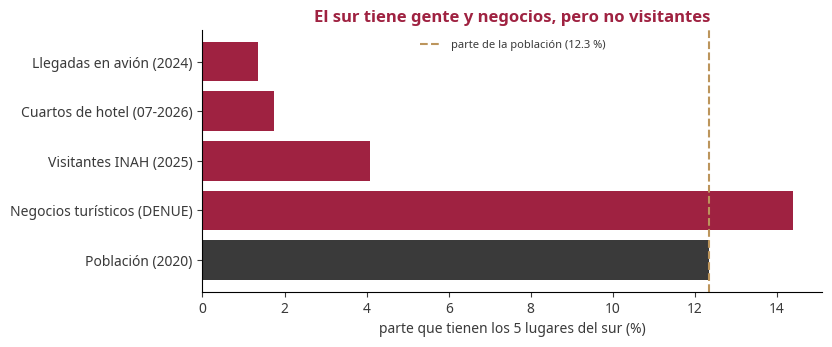

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(conc))
ax.barh(y, conc["parte de los 5 (%)"], color=[GUINDA] * 4 + [GRIS])
ax.axvline(pob_5, color=DORADO, ls="--", label=f"parte de la población ({pob_5:.1f} %)")
ax.set_yticks(y, conc["dimensión"]); ax.invert_yaxis(); ax.set_xlabel("parte que tienen los 5 lugares del sur (%)")
ax.legend(frameon=False, fontsize=8); ax.set_title("El sur tiene gente y negocios, pero no visitantes")
guardar(fig, "2_parte_de_los_5")

## 4. ¿Por qué estos 5 lugares? Los criterios
Usamos cinco criterios. Tres se miden con datos oficiales y dos (sargazo y fragilidad ecológica) no tienen serie
oficial: se registran como **evidencia documental** con su fuente, marcados como tal.

| # | Criterio | Cómo se mide |
|---|---|---|
| 1 | Sin sargazo en rojo | Evidencia documental (ECOSUR, prensa con fecha) |
| 2 | Sin cierres recientes | Meses seguidos abierta (INAH): pasa con al menos 12 y sin cierres en 2026 |
| 3 | Sin saturación | Ocupación hotelera 2024, visitantes INAH por residente, negocios turísticos por mil habitantes |
| 4 | Sin fragilidad grave | Viviendas sin agua y sin drenaje (Censo 2020) y evidencia documental |
| 5 | Con datos para medirlos | Cuántas series oficiales tiene |

**Por qué 12 meses y no "ningún cierre desde 2024".** Con esa regla saldrían la Ruta y Oxtankah, que cerraron por obras
en 2024 y ya reabrieron. Lo que importa al viajero es que hoy esté abierta y lleve un año sin cerrar.

In [5]:
crit = pd.read_parquet(GOLD / "criterios_regiones.parquet").set_index("region")
ruta, tulum = crit.loc["Ruta arqueológica del sur"], crit.loc["Tulum"]
print(f"Presión en la Ruta: {ruta.visitantes_inah_2025:,.0f} visitantes ÷ {ruta.poblacion_2020:,.0f} habitantes = "
      f"{ruta.c3_visitantes_inah_por_residente:.2f} por habitante")
print(f"Presión en Tulum: {tulum.visitantes_inah_2025:,.0f} ÷ {tulum.poblacion_2020:,.0f} = {tulum.c3_visitantes_inah_por_residente:.2f}")
crit[["papel", "c1_sargazo", "c2_pasa", "c3_ocupacion_2024_pct", "c3_visitantes_inah_por_residente",
      "c3_negocios_turisticos_por_mil", "c4_viviendas_sin_drenaje_pct", "c5_series_oficiales"]]

Presión en la Ruta: 66,628 visitantes ÷ 6,098 habitantes = 10.93 por habitante
Presión en Tulum: 1,031,443 ÷ 33,374 = 30.91


,papel,c1_sargazo,c2_pasa,c3_ocupacion_2024_pct,c3_visitantes_inah_por_residente,c3_negocios_turisticos_por_mil,c4_viviendas_sin_drenaje_pct,c5_series_oficiales
region,,,,,,,,
Chetumal,promovida,vigilancia,True,58.0,NaN,8.5,1.1,4
Bahía Calderitas–Oxtankah,promovida,vigilancia,True,NaN,1.98,12.6,1.4,3
Ruta arqueológica del sur,promovida,no aplica,True,NaN,10.93,10.5,4.8,3
Maya Ka'an + Kantemó,promovida,no aplica,True,38.6,NaN,8.7,5.1,4
Laguna Milagros–Xul-Ha,promovida,no aplica,True,NaN,NaN,0.5,1.0,2
Cancún,referencia,afectada,True,76.1,0.10,5.7,1.7,5
Riviera Maya (Playa del Carmen),referencia,afectada,True,76.9,NaN,6.4,4.1,4
Tulum,referencia,afectada,False,73.7,30.91,26.5,3.2,5


La Ruta recibe 10.9 visitantes por habitante de sus pueblos de acceso; Tulum, 30.9. La Ruta tiene un
tercio de la presión de Tulum: no es poco, y por eso la campaña también le pone tope (la capacidad probada del notebook
6). Tulum, Cancún y la Riviera Maya quedan como referencia: tienen sargazo en 2026, ocupación arriba de 70 % y, en
Tulum, cierres de negocios.

**Un hallazgo que reportamos aunque no nos conviene.** En 2026, Kohunlich (+13.5 %) y Dzibanché (+69.2 %) crecen
contra los mismos meses de 2025, pero la Ruta completa baja 8.2 % porque Ichkabal cae 27.5 %. Nunca destacamos solo las
zonas que suben: sería escoger datos a conveniencia.

## 5. Análisis exploratorio
### Los visitantes del sur, mes por mes

nombre,Z.A de Ichkabal,Z.A. de Dzibanché-Kinichná,Z.A. de Kohunlich,Z.A. de Oxtankah
periodo,,,,
2016,0.0,14912.0,30567.0,10300.0
2017,0.0,17045.0,36105.0,11062.0
2018,0.0,21862.0,46890.0,12170.0
2019,0.0,21326.0,42813.0,13772.0
2020,0.0,7049.0,16776.0,6816.0
2021,0.0,9168.0,22425.0,7886.0
2022,0.0,11693.0,34602.0,8615.0
2023,0.0,9243.0,32079.0,6896.0
2024,0.0,945.0,6222.0,1603.0


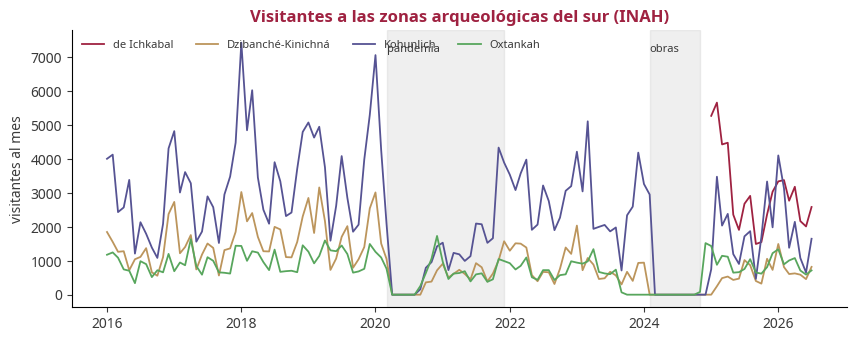

In [6]:
i = pd.read_parquet(SILVER / "inah", columns=["nombre", "periodo", "visitantes", "es_qroo", "papel_campana"])
i = i[i.es_qroo & (i.papel_campana == "promovida")].assign(periodo=lambda x: pd.to_datetime(x.periodo.astype(str)))
zonas = i.groupby(["periodo", "nombre"]).visitantes.sum().unstack().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.6))
for z, color in zip(zonas.columns, PALETA):
    ax.plot(zonas.index, zonas[z], color=color, lw=1.3, label=z.replace("Z.A. de ", "").replace("Z.A ", ""))
for ini, fin, texto in [("2020-03-01", "2021-12-01", "pandemia"), ("2024-02-01", "2024-11-01", "obras")]:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=GRIS, alpha=0.08); ax.text(pd.Timestamp(ini), ax.get_ylim()[1] * 0.92, texto, fontsize=8)
ax.set_ylabel("visitantes al mes"); ax.legend(frameon=False, fontsize=8, ncol=4); ax.set_title("Visitantes a las zonas arqueológicas del sur (INAH)")
guardar(fig, "2_visitantes_sur")
anual = zonas.groupby(zonas.index.year).sum().loc[2016:2025]
anual.round(0)

Se ven las dos rupturas que obligan a marcar meses que no sirven para entrenar (notebook 4): la pandemia
(2020–2021) y el cierre por obras de 2024. Ichkabal abrió en 2025 y ese año ya recibió más visitantes que Kohunlich.

### ¿Quién llega al sur? Extranjeros por avión
La campaña tiene que saber a quién le habla. DataTur publica las llegadas de extranjeros por aeropuerto y país.

In [7]:
n = pd.read_parquet(SILVER / "nacionalidad", columns=["aeropuerto", "anio", "pais", "llegadas_extranjeros", "es_qroo"])
n = n[n.es_qroo & (n.anio.astype(int) == 2025)]
por_aeropuerto = n.groupby("aeropuerto").llegadas_extranjeros.sum().sort_values(ascending=False)
print("Extranjeros que llegaron por avión en 2025:", por_aeropuerto.map("{:,.0f}".format).to_dict())
top = n.groupby("pais").llegadas_extranjeros.sum().nlargest(8)
(100 * top / n.llegadas_extranjeros.sum()).round(1).rename("% de los extranjeros de Quintana Roo")

Extranjeros que llegaron por avión en 2025: {'Cancún, Q. Roo': '9,408,423', 'A.I Tulum Felipe Carrillo Puerto, Q. Roo.': '323,948', 'Cozumel, Q. Roo': '192,206', 'Chetumal, Q. Roo': '250'}


pais
Estados Unidos    57.3
Canadá            17.1
Reino Unido        3.7
Argentina          2.6
Colombia           1.8
Francia            1.7
España             1.7
Alemania           1.3
Name: % de los extranjeros de Quintana Roo, dtype: float64

En 2025, a Chetumal llegaron por avión **250 extranjeros**; a Cancún, millones. El extranjero no llega al
sur por avión: si llega, es por tierra desde el norte o desde Belice. Por eso la campaña le habla al turista **que ya
está en el norte** ("¿Ibas al norte?") y no compra anuncios en el extranjero (notebook 7).

### La ocupación del norte, semana por semana

,count,mean,50%,max
centro,,,,
Akumal,239.0,74.3,77.9,94.9
Cancun,239.0,74.2,75.1,89.2
Cozumel,239.0,53.0,52.8,78.0
Isla Mujeres,239.0,51.8,53.4,78.5
Playa Del Carmen,239.0,68.7,70.2,91.2
Playacar,239.0,83.2,84.2,96.6
Riviera Maya,239.0,73.1,75.3,90.1


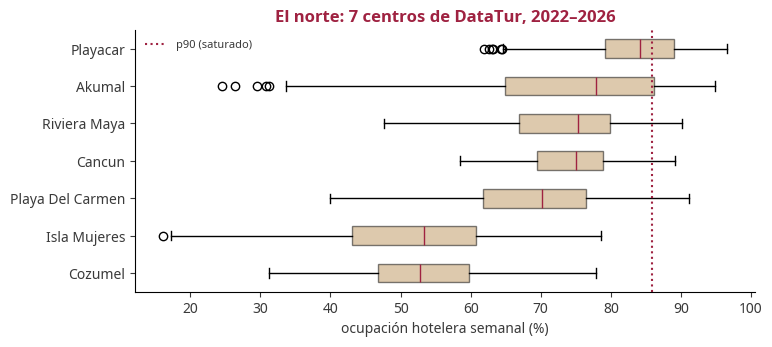

In [8]:
o = pd.read_parquet(SILVER / "datatur_ocupacion", columns=["centro", "es_qroo", "frecuencia", "periodo", "cuartos_ocupados", "cuartos_disponibles"])
o = o[o.es_qroo & (o.frecuencia == "semanal")].copy()
o["ocupacion"] = 100 * o.cuartos_ocupados / o.cuartos_disponibles                # nunca se promedian porcentajes
fig, ax = plt.subplots(figsize=(8, 3.4))
orden = o.groupby("centro").ocupacion.median().sort_values().index
ax.boxplot([o[o.centro == c].ocupacion.dropna() for c in orden], labels=orden, vert=False, patch_artist=True,
           boxprops=dict(facecolor=DORADO, alpha=0.5), medianprops=dict(color=GUINDA))
ax.axvline(np.quantile(o.ocupacion.dropna(), 0.9), color=GUINDA, ls=":", label="p90 (saturado)")
ax.set_xlabel("ocupación hotelera semanal (%)"); ax.legend(frameon=False, fontsize=8); ax.set_title("El norte: 7 centros de DataTur, 2022–2026")
guardar(fig, "2_ocupacion_norte")
o.groupby("centro").ocupacion.describe()[["count", "mean", "50%", "max"]].round(1)

## 6. La lluvia y el calor: ¿de dónde salen?
### Dos fuentes, dos usos
| | **Reanálisis ERA5** (Open-Meteo) | **Normales climatológicas del SMN** (CONAGUA) |
|---|---|---|
| Qué es | Un modelo meteorológico que **asimila observaciones** de satélites, barcos y estaciones y da el clima de cada día en una malla de unos 28 km | El **promedio de 30 años (1991–2020)** medido en una estación real |
| Qué trae | Lluvia, temperatura y viento de **cada día desde 1950** y de cada hora desde 2019, sin huecos | Lluvia normal y temperatura máxima normal de **cada mes del año** |
| Para qué lo usamos | Los **modelos**: la regresión con clima, la sensibilidad, el Isolation Forest y la Torre en vivo, que necesitan el clima de cada mes de cada año | Lo que ve **el viajero** en la página: "en octubre llueven 210 mm" y los consejos de calor |

### Cómo bajamos ERA5
Open-Meteo tiene una API pública de archivo histórico. Para cada uno de 8 puntos (Chetumal, Kohunlich, Felipe Carrillo
Puerto, Cancún, Playa del Carmen, Tulum, Bacalar y Cobá) pedimos los datos diarios década por década (`lluvia_mm`,
`temp_max_c`, `viento_max_kmh`) y los horarios año por año. Cada respuesta es un JSON que se guarda en Bronze con su
SHA-256; en Silver se juntan en `clima_diario` (224,232 días) y `clima_horario` (542,784 horas), sin un solo nulo.

**La lluvia del mes** es la **suma** de la lluvia de sus días, y la **normal** de un mes es el promedio de esas sumas
entre años. Un detalle técnico que nos costó un error: el año viene como **categoría** (la tabla está partida por año en
Parquet). Si no se convierte a número antes de agrupar, pandas crea combinaciones vacías de punto y año que cuentan como
lluvia cero, y la lluvia anual de Chetumal sale en 483 mm en lugar de 1,239.

In [9]:
dia = pd.read_parquet(SILVER / "clima_diario", columns=["punto", "anio", "mes", "lluvia_mm", "temp_max_c"])
dia["anio"], dia["punto"] = dia.anio.astype(int), dia.punto.astype(str)        # categoría → número y texto
mal = pd.read_parquet(SILVER / "clima_diario", columns=["punto", "anio", "mes", "lluvia_mm"])   # sin convertir: el error
mal = mal[mal.anio.astype(int).between(1991, 2020)].groupby(["punto", "anio", "mes"], observed=False).lluvia_mm.sum()
print(f"Lluvia anual de Chetumal sin convertir el año: {mal.loc['chetumal'].groupby(level='mes').mean().sum():,.0f} mm (mal)")

d30 = dia[dia.anio.between(1991, 2020)]                                         # el mismo periodo de las normales del SMN
mensual = d30.groupby(["punto", "anio", "mes"]).agg(lluvia=("lluvia_mm", "sum"), tmax=("temp_max_c", "mean"))
era5 = mensual.groupby(["punto", "mes"]).mean()                                  # normal de ERA5: promedio entre años
print(f"Lluvia anual de Chetumal convertida bien: {era5.loc['chetumal'].lluvia.sum():,.0f} mm")

Lluvia anual de Chetumal sin convertir el año: 483 mm (mal)
Lluvia anual de Chetumal convertida bien: 1,239 mm


### Cómo leímos las normales del SMN
El Servicio Meteorológico Nacional publica un archivo de texto por estación (`nor9120_<estación>.txt`). Elegimos la
estación más cercana a cada punto con al menos 25 años con dato: **23032 Chetumal (DGE)**, **23016 Nicolás Bravo km 71**
(la más cercana a Kohunlich, a 16 km) y **23155 Cancún**. Del texto se leen dos bloques: *PRECIPITACIÓN* y *TEMPERATURA
MÁXIMA*, cada uno con su renglón *NORMAL* (los 12 meses) y su renglón *AÑOS CON DATOS*.

In [10]:
carpeta = sorted((RAIZ / "datos" / "bronze" / "smn").glob("*/"))[-1]
ESTACIONES = {"chetumal": 23032, "kohunlich": 23016, "cancun": 23155}
filas = []
for punto, estacion in ESTACIONES.items():
    lineas = [l.strip() for l in (carpeta / f"nor9120_{estacion}.txt").read_bytes().decode("utf-8", errors="replace").splitlines()]
    def bloque(titulo):
        i = next(k for k, l in enumerate(lineas) if l.startswith(titulo))      # dónde empieza el bloque
        normal = next(l for l in lineas[i:] if l.startswith("NORMAL"))
        anios = next(l for l in lineas[i:] if "CON DATOS" in l)
        return [float(x) for x in normal.split()[1:13]], [int(x) for x in anios.split()[-12:]]
    lluvia, anios_ll = bloque("PRECIPITACI")
    tmax, _ = bloque("TEMPERATURA M")                                            # TEMPERATURA MÁXIMA
    filas += [{"punto": punto, "estacion": estacion, "mes": m + 1, "lluvia_smn": lluvia[m], "tmax_smn": tmax[m], "años": anios_ll[m]}
              for m in range(12)]
smn = pd.DataFrame(filas)
silver_smn = pd.read_parquet(SILVER / "clima_normal_smn").sort_values(["punto", "mes"])
coincide("lluvia normal del SMN", smn.sort_values(["punto", "mes"]).lluvia_smn, silver_smn.lluvia_normal_mm)
print(lineas[:6])

✓ lluvia normal del SMN: coincide con el proyecto (diferencia máxima 0)
['COMISIÓN NACIONAL DEL AGUA', 'COORDINACIÓN GENERAL DEL SERVICIO METEOROLÓGICO NACIONAL', 'BASE DE DATOS CLIMATOLÓGICA NACIONAL', '', 'NORMAL CLIMATOLÓGICA 1991-2020', 'EMISIÓN   : 16/10/2026']


,lluvia anual SMN (mm),lluvia anual ERA5 (mm),ERA5 ÷ SMN,correlación de la forma,temp. máx. ERA5 − SMN (°C)
punto,,,,,
cancun,1371.3,1216.850,0.887,0.831,-4.446
chetumal,1355.5,1239.467,0.914,0.985,-3.124
kohunlich,1151.5,1115.100,0.968,0.959,-1.967


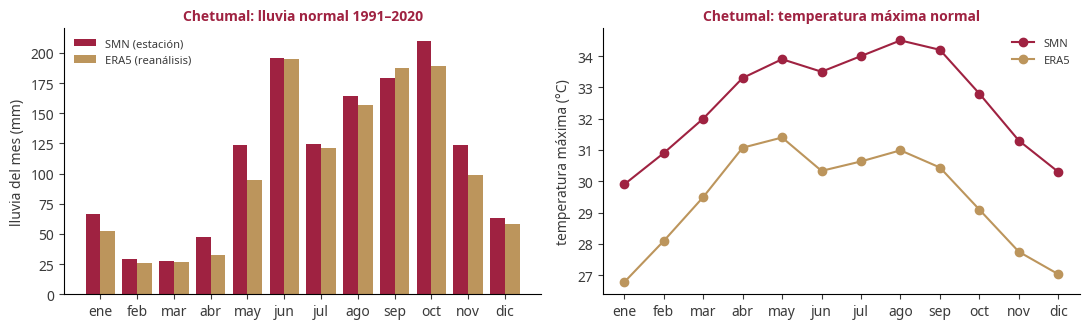

In [11]:
comp = smn.merge(era5.reset_index().rename(columns={"lluvia": "lluvia_era5", "tmax": "tmax_era5"}), on=["punto", "mes"])
resumen = comp.groupby("punto").apply(lambda g: pd.Series({
    "lluvia anual SMN (mm)": g.lluvia_smn.sum(), "lluvia anual ERA5 (mm)": g.lluvia_era5.sum(),
    "ERA5 ÷ SMN": g.lluvia_era5.sum() / g.lluvia_smn.sum(), "correlación de la forma": np.corrcoef(g.lluvia_era5, g.lluvia_smn)[0, 1],
    "temp. máx. ERA5 − SMN (°C)": (g.tmax_era5 - g.tmax_smn).mean()}))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
c = comp[comp.punto == "chetumal"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ejes[0].bar(np.arange(12) - 0.2, c.lluvia_smn, 0.4, color=GUINDA, label="SMN (estación)")
ejes[0].bar(np.arange(12) + 0.2, c.lluvia_era5, 0.4, color=DORADO, label="ERA5 (reanálisis)")
ejes[0].set_xticks(range(12), MESES); ejes[0].set_ylabel("lluvia del mes (mm)"); ejes[0].legend(frameon=False, fontsize=8)
ejes[0].set_title("Chetumal: lluvia normal 1991–2020", fontsize=10)
ejes[1].plot(MESES, c.tmax_smn, color=GUINDA, marker="o", label="SMN"); ejes[1].plot(MESES, c.tmax_era5, color=DORADO, marker="o", label="ERA5")
ejes[1].set_ylabel("temperatura máxima (°C)"); ejes[1].legend(frameon=False, fontsize=8); ejes[1].set_title("Chetumal: temperatura máxima normal", fontsize=10)
fig.tight_layout(); guardar(fig, "2_era5_contra_smn")
resumen.round(3)

**Lo que encontramos (decisión 32).**
- **La forma de la lluvia coincide**: correlación de 0.96 a 0.99 en Chetumal y Kohunlich. ERA5 da de 3 % a 9 % menos
  lluvia al año que la estación. Para los modelos importa la **variación** (si un mes llovió más o menos que lo normal),
  y esa ERA5 la tiene bien.
- **El calor no coincide**: ERA5 da una temperatura máxima **2 a 3 °C más baja** que la estación (4.5 °C en Cancún),
  porque su celda de 28 km mezcla tierra con mar y selva. Para el viajero eso importa: "33 °C" no es lo mismo que "30 °C".

**La regla que fijamos:** lo que ve el viajero sale de la **estación del SMN** (lo medido); lo que necesitan los modelos,
del **reanálisis ERA5** (la serie mes a mes completa). Así cada fuente se usa para lo que sirve. Antes la página usaba
ERA5 también para el viajero; lo cambiamos en la revisión final del proyecto. La única excepción es la Riviera Maya:
no hay una estación del SMN con normales 1991–2020 en Playa del Carmen, así que ahí la página usa ERA5 y lo dice en la
fuente. Lo comprobamos en el calendario de la página:

In [12]:
cal = pd.read_parquet(GOLD / "pronostico_calendario.parquet")
x = cal[cal.punto_clima.isin(ESTACIONES)].merge(smn, left_on=["punto_clima", "mes"], right_on=["punto", "mes"])
coincide("lluvia normal que ve el viajero = la del SMN", x.lluvia_normal_mm, x.lluvia_smn)
print("Fuente del clima en el calendario:", sorted(cal.fuente_clima.dropna().unique()))

✓ lluvia normal que ve el viajero = la del SMN: coincide con el proyecto (diferencia máxima 0)
Fuente del clima en el calendario: ['ERA5 (Open-Meteo), promedio 1991–2020', 'SMN-CONAGUA, estación 23016 NICOLAS BRAVO KM. 71', 'SMN-CONAGUA, estación 23032 CHETUMAL (DGE)', 'SMN-CONAGUA, estación 23155 CANCUN']


## 7. Variables, actores y relaciones

| Tipo | Variables (fuente) | Módulo |
|---|---|---|
| **Presión** (demanda que llega) | Llegadas en Tren Maya, cruceristas, cruces desde Belice, pasajeros en avión, visitantes INAH, ocupación hotelera (SITUR-Q, INAH, DataTur) | Radar, Pronóstico, Torre |
| **Capacidad** (lo que se puede recibir) | Cuartos de hotel, hoteles (SITUR-Q), negocios turísticos (DENUE), capacidad probada | Radar, IO |
| **Comunidad** | Población, viviendas con agua y drenaje (Censo 2020) | Radar, IO |
| **Contexto** | Lluvia, temperatura, viento (ERA5, SMN), tormentas (HURDAT2), tipo de cambio (FRED) | Pronóstico, Torre |
| **Huecos declarados** | Afluencia, derrama de turistas y de visitantes (SITUR-Q) | — |

**Actores:** las comunidades de los 5 lugares (229,247 habitantes), sus negocios turísticos (1,966), el Tren Maya
(58,086 personas bajaron en Chetumal y Maya Ka'an en 2025), la frontera con Belice (653,306 cruces en 2025), el INAH
(77,645 visitantes en las 4 zonas en 2025), el gobierno del estado (SITUR-Q) y la Secretaría de Turismo (DataTur).

**La relación central:** la presión está concentrada en el norte (HHI* de 0.81 en avión) mientras el sur tiene gente y
negocios con poca demanda ($\rho$ de 0.11 a 0.33). La campaña busca mover demanda del norte al sur **sin** trasladar la
saturación: por eso cada lugar tiene tope de capacidad (notebook 6) y la Torre vigila cada semana.

## 8. Resumen de decisiones

| Decisión | Elegimos | Por qué | Qué descartamos |
|---|---|---|---|
| Medida de concentración | HHI normalizado | Estándar, se resuelve a mano, compara dimensiones | Gini (inestable con 4 aeropuertos) |
| Unidad de los 5 lugares | Localidades del Censo | 4 de 5 están en el mismo municipio | El municipio |
| Comparación | Razón contra la población | Dice si reciben "poco" para su tamaño | Comparar cifras absolutas |
| Criterio de cierres | 12 meses abierta y sin cierres en 2026 | Lo que le importa al viajero hoy | "Ningún cierre desde 2024" (sacaría la Ruta) |
| Sargazo y fragilidad | Evidencia documental marcada | No hay serie oficial | Inventar un índice |
| Clima del viajero | Normales del SMN | Medido en estación; ERA5 da 2–3 °C menos | ERA5 para todo |
| Clima de los modelos | ERA5 | Serie diaria completa desde 1950 | Estación del SMN (huecos, sin serie mes a mes publicada) |

**Qué decisión alimenta.** La medición de la concentración justifica la campaña; los criterios definen qué lugares se
promueven; y las variables de presión y capacidad son las que entran al índice del Radar (notebook 3).